# GameTheory-17e — Persuasion bayésienne : concavification contre programme linéaire

**Série** : GameTheory (strate 7, notebook 17e) · **Kernel** : .NET C# · **Durée** : ~45 min

**Parité C#** — jumeau .NET du carnet Python du même nom. Mêmes instances, mêmes
valeurs, mêmes exercices ; seuls changent le solveur (`scipy.linprog` HiGHS →
**GLOP** d'OrTools) et le rendu (matplotlib → ScottPlot). Le protocole et les
résultats sont identiques — c'est précisément le point de la parité.

Un **persuadeur** ne peut pas mentir, mais il peut choisir *ce qu'il montre*. Il
s'engage sur une structure d'information — un **signal** — avant que le
**receveur** agisse. Le receveur observe un message, met à jour sa croyance par la
règle de Bayes, puis prend l'action qui maximise *son* utilité. Le persuadeur n'a
aucun pouvoir sur l'action : sa seule prise est sur la **croyance**.

Le résultat central (Kamenica 2019) : la valeur optimale du persuadeur est la
**concavification** de sa fonction de valeur, évaluée au prior. Ce carnet la
**calcule par deux méthodes indépendantes** et exige qu'elles concordent.

## Ce que ce carnet fait, et ce qu'il ne refait pas

| Voisin de la série | ce qu'il fait | ce que fait celui-ci |
|---|---|---|
| `GameTheory-17d-Lean-Screening-Signaling-Lean` (lake `asymmetric_information_lean`) | le **signal est l'action** du vendeur : son type se révèle par ce qu'il fait | le persuadeur **s'engage sur une structure d'information**, sans aucune action observable |
| `GameTheory-16c-Extraction-de-Revenu-DSIC-IR-Python` | on conçoit la **règle d'allocation** (mécanisme) | on conçoit le **signal** ; l'allocation reste choisie par le receveur |
| `GameTheory-17b-Asymmetric-Information-Python` | l'asymétrie d'information est **descriptive** | l'asymétrie est **choisie** par le persuadeur |

Les trois forment une famille — conception de mécanisme, signalement, conception
d'information. Ce notebook est le **troisième volet**, pas un doublon des deux
premiers.


## 1. Le cadre

- un état $w \in W$, de loi a priori $\mu_0 \in \Delta(W)$ ;
- un receveur qui choisit $a \in A$, d'utilité $u_R(a, w)$ ;
- un persuadeur d'utilité $u_S(a, w)$.

Le persuadeur choisit un **signal** : une application de $W$ vers les lois sur un
ensemble de messages. Un signal équivaut à une **loi jointe** $q(w, s) \ge 0$ sur
(état, message) vérifiant la plausibilité bayésienne

$$\sum_s q(w, s) = \mu_0(w) \qquad \forall w \in W .$$

Le message $s$ n'a pas de sens intrinsèque : tout ce qui compte est la
**posterior** qu'il induit, $\mu_s(w) = q(w, s) / q(s)$. Le receveur y joue une
meilleure réponse, et le persuadeur anticipe cette réponse.

**Le principe de révélation s'applique.** On peut supposer que chaque message
*recommande* une action $a_s \in A$, et exiger la contrainte d'**obéissance**

$$\sum_w q(w, s)\,\bigl[u_R(a_s, w) - u_R(a', w)\bigr] \;\ge\; 0
\qquad \forall s,\ \forall a' \neq a_s .$$

$|W|$ messages suffisent. C'est cette forme — **linéaire en $q$** — qui rend le
problème soluble par un programme linéaire, et c'est la méthode A ci-dessous.


## 2. Plan et critère de réussite

1. **Méthode A — programme linéaire** sur la loi jointe $q$, en énumérant l'action
   recommandée par chaque message.
2. **Méthode B — concavification géométrique** : $v(\mu) = \max_a \sum_w \mu(w)
   u_S(a, w)$ évaluée sur une grille du simplexe, puis enveloppe concave au prior.

**Le critère est falsifiable** : les deux méthodes doivent rendre la **même
valeur** au même prior, à une tolérance déclarée, sur **trois instances** — dont
une où l'optimum est **non partitionnel** (le signal optimal fait strictement
mieux que la divulgation complète), et une où il ne l'est pas (contrôle négatif).

Un désaccord entre les deux méthodes est un **bug de l'une des deux**, pas une
subtilité : elles calculent la même quantité par deux chemins qui ne partagent
aucun code.


## 3. Croyance, meilleure réponse, valeur

Commençons par l'objet que tout le reste réutilise : la **valeur du persuadeur en
une posterior** $\mu$. C'est le maximum de son utilité sur les meilleures
réponses du receveur — les égalités étant tranchées **en sa faveur**.

Cette convention n'est pas un détail : c'est exactement ce qu'autorise la
contrainte d'obéissance non stricte du programme linéaire, et c'est ce qui rend la
concavification et le programme linéaire comparables. La valeur sans information
n'est que ce même objet évalué au prior.

Toutes les fonctions du carnet vivent dans une classe `Persuasion` (solveur LP =
GLOP d'OrTools) ; les cellules suivantes l'appellent.


In [1]:
#r "nuget: Google.OrTools, 9.15.6755"
using System;
using System.Collections.Generic;
using System.Linq;
using Google.OrTools.LinearSolver;

// Types de retour (lois jointes, posteriors, instances, ligne de mesure).
public record Sol(double Valeur, double[,] Q, int[] Affectation);
public record Post(int Message, double Masse, double[] Posterior);
public record Instance(string Nom, string[] Etats, string[] Actions, double[] Valeurs,
                       double[] Mu0, double[,] UR, double[,] US);
public record Mesure(string Instance, double SansInfo, double Optimal, double Divulgation,
                     double Grille, double EcartGrille, bool Partitionnel, Sol Sol);

// Toutes les fonctions du carnet, dans une classe (le solveur LP est GLOP/OrTools).
public static class Persuasion
{
    // --- fondations : meilleure reponse, valeur ---

    // Actions qui maximisent l'utilite esperee du receveur sous la posterior mu.
    public static List<int> MeilleuresReponses(double[] mu, double[,] uR, double tol = 1e-9)
    {
        int nA = uR.GetLength(0);
        var gains = new double[nA];
        for (int a = 0; a < nA; a++)
        {
            double g = 0;
            for (int w = 0; w < mu.Length; w++) g += uR[a, w] * mu[w];
            gains[a] = g;
        }
        double sommet = gains.Max();
        return Enumerable.Range(0, nA).Where(a => gains[a] >= sommet - tol).ToList();
    }

    // v(mu) : utilite du persuadeur quand le receveur observe exactement mu.
    // Les egalites de meilleure reponse sont tranchees en sa faveur (non strict).
    public static double ValeurPersuadeur(double[] mu, double[,] uR, double[,] uS, double tol = 1e-9)
    {
        double best = double.NegativeInfinity;
        foreach (int a in MeilleuresReponses(mu, uR, tol))
        {
            double s = 0;
            for (int w = 0; w < mu.Length; w++) s += uS[a, w] * mu[w];
            if (s > best) best = s;
        }
        return best;
    }

    // Le receveur agit sur le prior : aucune information n'est transmise.
    public static double ValeurSansInformation(double[] mu0, double[,] uR, double[,] uS)
        => ValeurPersuadeur(mu0, uR, uS);

    // Valeur du signal revelant l'etat : le receveur voit w avant d'agir.
    public static double ValeurDivulgationComplete(double[] mu0, double[,] uR, double[,] uS)
    {
        int n = mu0.Length;
        double tot = 0;
        for (int w = 0; w < n; w++)
        {
            var e = new double[n];
            e[w] = 1.0;                       // eye(n)[w]
            tot += mu0[w] * ValeurPersuadeur(e, uR, uS);
        }
        return tot;
    }

    // --- solveur LP generique (GLOP) ---

    // min c.x  s.c.  A_ub.x <= b_ub,  A_eq.x == b_eq,  x >= 0.  Retourne (statut, objectif, x).
    private static (int Statut, double Objectif, double[] X) SolveLp(
        double[] c, double[][]? aUb, double[]? bUb, double[,]? aEq, double[]? bEq, int nVar)
    {
        var solver = Solver.CreateSolver("GLOP");
        var vars = new Variable[nVar];
        for (int i = 0; i < nVar; i++)
            vars[i] = solver.MakeNumVar(0.0, double.PositiveInfinity, $"x{i}");

        LinearExpr obj = c[0] * vars[0];
        for (int i = 1; i < nVar; i++) obj += c[i] * vars[i];
        solver.Minimize(obj);

        if (aUb != null)
            for (int r = 0; r < aUb.Length; r++)
            {
                var con = solver.MakeConstraint(double.NegativeInfinity, bUb![r], $"ub{r}");
                for (int i = 0; i < nVar; i++)
                    if (aUb[r][i] != 0.0) con.SetCoefficient(vars[i], aUb[r][i]);
            }
        if (aEq != null)
            for (int r = 0; r < aEq.GetLength(0); r++)
            {
                var con = solver.MakeConstraint(bEq![r], bEq[r], $"eq{r}");
                for (int i = 0; i < nVar; i++)
                    if (aEq[r, i] != 0.0) con.SetCoefficient(vars[i], aEq[r, i]);
            }

        var rs = solver.Solve();
        int st = rs == Solver.ResultStatus.OPTIMAL ? 0 : (int)rs;
        double objv = solver.Objective().Value();
        var x = new double[nVar];
        for (int i = 0; i < nVar; i++) x[i] = vars[i].SolutionValue();
        return (st, objv, x);
    }

    // --- Methode A : programme lineaire sur la loi jointe ---

    // Maximise sur la loi jointe (etat, message) ; enumere l'affectation (action
    // par message), fixe l'obeissance sur cette affectation, resout, garde le meilleur.
    public static Sol SignalOptimalLp(double[] mu0, double[,] uR, double[,] uS)
    {
        int nE = mu0.Length, nA = uR.GetLength(0), nM = nE;   // |W| messages suffisent
        int nVar = nM * nE;
        Sol? meilleur = null;
        foreach (var aff in ProduitCartesien(nA, nM))
        {
            var c = new double[nVar];
            for (int s = 0; s < nM; s++)
                for (int w = 0; w < nE; w++)
                    c[s * nE + w] = -uS[aff[s], w];

            var aEq = new double[nE, nVar];
            var bEq = (double[])mu0.Clone();
            for (int w = 0; w < nE; w++)
                for (int s = 0; s < nM; s++)
                    aEq[w, s * nE + w] = 1.0;               // plausibilite : sum_s q(w,s) = mu0(w)

            var aUb = new List<double[]>();
            var bUb = new List<double>();
            for (int s = 0; s < nM; s++)
                for (int a = 0; a < nA; a++)
                {
                    if (a == aff[s]) continue;
                    var ligne = new double[nVar];
                    for (int w = 0; w < nE; w++)
                        ligne[s * nE + w] = -(uR[aff[s], w] - uR[a, w]);   // obeissance
                    aUb.Add(ligne);
                    bUb.Add(0.0);
                }

            var (st, objv, x) = SolveLp(c, aUb.ToArray(), bUb.ToArray(), aEq, bEq, nVar);
            if (st == 0)
            {
                double valeur = -objv;
                if (meilleur is null || valeur > meilleur.Valeur + 1e-12)
                {
                    var q = new double[nM, nE];
                    for (int s = 0; s < nM; s++)
                        for (int w = 0; w < nE; w++)
                            q[s, w] = x[s * nE + w];
                    meilleur = new Sol(valeur, q, (int[])aff.Clone());
                }
            }
        }
        return meilleur!;
    }

    // --- Methode B : concavification sur grille ---

    // Points du simplexe de pas 1/resolution (lois sur n_etats etats).
    public static double[,] SimplexeGrille(int nEtats, int resolution)
    {
        var pts = new List<double[]>();
        void parcours(List<double> prefixe, int reste, int parts)
        {
            if (parts == 1) { prefixe.Add(reste); pts.Add(prefixe.ToArray()); return; }
            for (int k = 0; k <= reste; k++)
            {
                var p = new List<double>(prefixe) { k };
                parcours(p, reste - k, parts - 1);
            }
        }
        parcours(new List<double>(), resolution, nEtats);
        var g = new double[pts.Count, nEtats];
        for (int i = 0; i < pts.Count; i++)
            for (int j = 0; j < nEtats; j++)
                g[i, j] = pts[i][j] / resolution;
        return g;
    }

    // Enveloppe concave de v, evaluee sur une grille du simplexe.
    // Approximation INTERIEURE : la valeur rendue est toujours <= l'optimum exact.
    public static double ConcavificationGrille(double[] mu0, double[,] uR, double[,] uS, int resolution)
    {
        int nE = mu0.Length;
        var grille = SimplexeGrille(nE, resolution);
        int n = grille.GetLength(0);
        var valeurs = new double[n];
        for (int i = 0; i < n; i++)
        {
            var mu = new double[nE];
            for (int w = 0; w < nE; w++) mu[w] = grille[i, w];
            valeurs[i] = ValeurPersuadeur(mu, uR, uS);
        }
        // LP : min -valeurs.lambda  s.c.  sum lambda = 1,  sum_i lambda_i * grille_i = mu0
        var c = valeurs.Select(v => -v).ToArray();
        var aEq = new double[nE + 1, n];
        var bEq = new double[nE + 1];
        for (int i = 0; i < n; i++) aEq[0, i] = 1.0;
        bEq[0] = 1.0;
        for (int w = 0; w < nE; w++)
        {
            bEq[w + 1] = mu0[w];
            for (int i = 0; i < n; i++) aEq[w + 1, i] = grille[i, w];
        }
        var (st, objv, _) = SolveLp(c, null, null, aEq, bEq, n);
        if (st != 0) throw new InvalidOperationException($"concavification irresoluble (statut {st})");
        return -objv;
    }

    // --- lecture de la loi jointe ---

    // Vrai si aucun etat n'envoie deux messages distincts.
    public static bool EstPartitionnel(double[,] q, double tol = 1e-7)
    {
        int nM = q.GetLength(0), nE = q.GetLength(1);
        for (int w = 0; w < nE; w++)
        {
            int nbPos = 0;
            for (int s = 0; s < nM; s++) if (q[s, w] > tol) nbPos++;
            if (nbPos > 1) return false;
        }
        return true;
    }

    // Posteriors induits par les messages de masse strictement positive.
    public static List<Post> Posteriors(double[,] q, double tol = 1e-7)
    {
        int nM = q.GetLength(0), nE = q.GetLength(1);
        var outList = new List<Post>();
        for (int s = 0; s < nM; s++)
        {
            double masse = 0;
            for (int w = 0; w < nE; w++) masse += q[s, w];
            if (masse > tol)
            {
                var post = new double[nE];
                for (int w = 0; w < nE; w++) post[w] = q[s, w] / masse;
                outList.Add(new Post(s, masse, post));
            }
        }
        return outList;
    }

    // --- confrontation des deux methodes ---

    // Confronte les deux methodes sur une instance et rend la ligne de mesure.
    public static Mesure Mesurer(Instance inst, int resolution = 10, double tol = 1e-6)
    {
        var sol = SignalOptimalLp(inst.Mu0, inst.UR, inst.US);
        if (sol is null || sol.Valeur <= double.NegativeInfinity)
            throw new InvalidOperationException($"le programme lineaire a echoue sur {inst.Nom}");
        double concav = ConcavificationGrille(inst.Mu0, inst.UR, inst.US, resolution);
        // Invariant : la grille est une approximation interieure, elle ne peut pas
        // faire mieux que l'optimum exact. Un depassement serait un bug, pas un ecart.
        if (concav > sol.Valeur + tol)
            throw new InvalidOperationException(
                $"la concavification sur grille depasse le programme lineaire ({concav} > {sol.Valeur})");
        return new Mesure(
            inst.Nom,
            ValeurSansInformation(inst.Mu0, inst.UR, inst.US),
            sol.Valeur,
            ValeurDivulgationComplete(inst.Mu0, inst.UR, inst.US),
            concav,
            sol.Valeur - concav,
            EstPartitionnel(sol.Q),
            sol);
    }

    // Imprime la ligne de mesure et la posterior de chaque message du signal.
    public static void AfficherLigne(Mesure m)
    {
        Console.WriteLine($"--- {m.Instance}");
        Console.WriteLine($"    sans information       : {m.SansInfo:F6}");
        Console.WriteLine($"    signal optimal (PL)    : {m.Optimal:F6}");
        Console.WriteLine($"    divulgation complete   : {m.Divulgation:F6}");
        Console.WriteLine($"    concavification grille : {m.Grille:F6}   (ecart au PL {m.EcartGrille:E3})");
        Console.WriteLine($"    signal optimal partitionnel ? {(m.Partitionnel ? "oui" : "non")}");
        foreach (var p in Posteriors(m.Sol.Q))
            Console.WriteLine($"      message {p.Message} : masse {p.Masse:F4} | posterior [{Fmt(p.Posterior)}] | recommande l'action {m.Sol.Affectation[p.Message]}");
    }

    // --- utilitaires ---

    public static string Fmt(double[] v) => string.Join(" ", v.Select(x => x.ToString("0.###")));

    // Produit cartésien : toutes les suites de longueur `reps` a valeurs dans [0, n).
    public static List<int[]> ProduitCartesien(int n, int reps)
    {
        var res = new List<int[]> { new int[reps] };
        for (int r = 0; r < reps; r++)
        {
            var next = new List<int[]>();
            foreach (var p in res)
                for (int v = 0; v < n; v++)
                {
                    var q = (int[])p.Clone();
                    q[r] = v;
                    next.Add(q);
                }
            res = next;
        }
        return res;
    }

    // Equivalence de l'assert Python : leve si la condition est fausse.
    public static void Require(bool cond, string msg)
    {
        if (!cond) throw new InvalidOperationException(msg);
    }
}

Console.WriteLine($".NET {Environment.Version} | OrTools GLOP {typeof(Solver).Assembly.GetName().Version} | solveur LP = GLOP");


Installed Packages Google.OrTools, 9.15.6755

.NET 10.0.15 | OrTools GLOP 9.15.6755.0 | solveur LP = GLOP



(70,31): warning CS8632: L'annotation pour les types référence Nullable doit être utilisée uniquement dans le code au sein d'un contexte d'annotations '#nullable'.

(70,46): warning CS8632: L'annotation pour les types référence Nullable doit être utilisée uniquement dans le code au sein d'un contexte d'annotations '#nullable'.

(70,62): warning CS8632: L'annotation pour les types référence Nullable doit être utilisée uniquement dans le code au sein d'un contexte d'annotations '#nullable'.

(70,77): warning CS8632: L'annotation pour les types référence Nullable doit être utilisée uniquement dans le code au sein d'un contexte d'annotations '#nullable'.

(112,12): warning CS8632: L'annotation pour les types référence Nullable doit être utilisée uniquement dans le code au sein d'un contexte d'annotations '#nullable'.



In [2]:
// Exemple guide : le juge d'un etat binaire.
// etats : 0 = innocent, 1 = coupable ; actions : 0 = acquitter, 1 = condamner.
var uR_JEU = new double[,] { { 1.0, 0.0 },    // acquitter : 1 si innocent, 0 si coupable
                             { 0.0, 1.0 } };  // condamner : 0 si innocent, 1 si coupable
var uS_PROC = new double[,] { { 0.0, 0.0 },   // le procureur ne tire rien d'un acquittement
                              { 1.0, 1.0 } }; // ... et tout d'une condamnation

foreach (double x in new[] { 0.30, 0.50, 0.70 })
{
    var mu = new[] { 1.0 - x, x };
    var br = Persuasion.MeilleuresReponses(mu, uR_JEU);
    Console.WriteLine($"P(coupable) = {x:F2} | meilleures reponses = [{string.Join(", ", br)}] | "
                      + $"v(mu) = {Persuasion.ValeurPersuadeur(mu, uR_JEU, uS_PROC):F4}");
}


P(coupable) = 0,30 | meilleures reponses = [0] | v(mu) = 0,0000


P(coupable) = 0,50 | meilleures reponses = [0, 1] | v(mu) = 1,0000


P(coupable) = 0,70 | meilleures reponses = [1] | v(mu) = 1,0000


Sur les trois lignes ci-dessus : à $P(\text{coupable}) = 0{,}50$ le juge est
**indifférent** entre acquitter et condamner, et la convention retenue compte la
condamnation — c'est la valeur du persuadeur. À $0{,}30$, le juge acquitte et le
procureur n'obtient rien ; à $0{,}70$, il condamne et le procureur obtient tout.

Sans information, le procureur n'a donc rien à espérer d'un prior de $0{,}30$.
Toute la question du carnet est : **combien peut-il gagner en choisissant ce que
le juge voit ?**


## 4. Méthode A — le programme linéaire sur la loi jointe

Variables $q(w, s) \ge 0$, avec $|W|$ messages. Pour une affectation d'actions
$(a_1, \dots, a_{|W|})$ fixée, le programme est linéaire :

$$\max_{q \ge 0}\ \sum_{s}\sum_{w} q(w, s)\,u_S(a_s, w)$$

sous les contraintes de plausibilité bayésienne et d'obéissance. On énumère les
$|A|^{|W|}$ affectations et on retient le meilleur des optima.

C'est la méthode **exacte** : aucune discrétisation. Le simplexe des posteriors
est exploré en entier, par la loi jointe. Le solveur est GLOP (OrTools) ; le
jumeau Python utilise HiGHS (`scipy.linprog`) — même formulation, même résultat.


In [3]:
// Methode A en action : le programme lineaire sur la loi jointe, sur le procureur.
var solA = Persuasion.SignalOptimalLp(new[] { 0.7, 0.3 }, uR_JEU, uS_PROC);
Console.WriteLine($"Methode A (PL) sur le procureur : valeur optimale = {solA.Valeur:F6}");
Console.WriteLine($"    partitionnel ? {Persuasion.EstPartitionnel(solA.Q)} ; messages de masse positive : "
                  + $"{Persuasion.Posteriors(solA.Q).Count}");


Methode A (PL) sur le procureur : valeur optimale = 0,600000


    partitionnel ? False ; messages de masse positive : 2


## 5. Méthode B — la concavification sur une grille du simplexe

La concavification est l'enveloppe concave **supérieure** de $v$ : au prior
$\mu_0$, c'est le maximum de $\sum_i \lambda_i v(\mu_i)$ sur les combinaisons
convexes de posteriors $\mu_i$ qui redonnent $\mu_0$ — c'est-à-dire sur les
loteries de posteriors **bayésiennes-plausibles** au sens de la moyenne.

Le calcul se fait sur une grille de pas $1/N$ du simplexe. C'est donc une
approximation **intérieure** : les posteriors accessibles sont restreints à la
grille, si bien que la valeur rendue ne peut **jamais dépasser** l'optimum exact —
à la tolérance de virgule flottante près — et elle y converge quand la grille
s'affine.

Une précision qui compte pour la lecture de la section 12 : deux grilles de pas
$1/N$ et $1/M$ ne sont emboîtées que si $N$ **divise** $M$. La convergence est donc
à entendre le long des chaînes de divisibilité, pas sur une liste de résolutions
quelconques.

Cette propriété d'encadrement est ce qui rend la comparaison des deux méthodes
informatrice : un dépassement au-delà du bruit numérique ne serait pas une
imprécision, ce serait une preuve de bug.


In [4]:
// Methode B en action : la concavification sur grille, sur le procureur.
// Elle ne depasse jamais l'optimum exact (approximation interieure) et y converge.
foreach (int res in new[] { 1, 2, 4, 10, 20 })
{
    double v = Persuasion.ConcavificationGrille(new[] { 0.7, 0.3 }, uR_JEU, uS_PROC, res);
    int nb = Persuasion.SimplexeGrille(2, res).GetLength(0);
    Console.WriteLine($"  grille 1/{res,2} ({nb,3} points) : {v:F6}");
}
Console.WriteLine("  borne haute (Methode A) : 0.600000 -- la grille reste en dessous ou l'atteint.");


  grille 1/ 1 (  2 points) : 0,300000


  grille 1/ 2 (  3 points) : 0,600000


  grille 1/ 4 (  5 points) : 0,600000


  grille 1/10 ( 11 points) : 0,600000


  grille 1/20 ( 21 points) : 0,600000


  borne haute (Methode A) : 0.600000 -- la grille reste en dessous ou l'atteint.


## 6. Les deux repères, et la lecture de la loi jointe

Trois quantités seront imprimées pour chaque instance, et c'est leur **écart**
qui porte le propos :

| Quantité | Ce qu'elle mesure |
|---|---|
| **sans information** | $v(\mu_0)$ — le receveur agit sur le prior ; le persuadeur ne transmet rien |
| **signal optimal** | la valeur du programme linéaire : le meilleur signal concevable |
| **divulgation complète** | le signal qui révèle l'état : le persuadeur obtient $v$ en chaque état dégénéré |

Un signal est dit **partitionnel** quand chaque état n'envoie qu'un seul message :
les messages découpent alors $W$ en morceaux, et la divulgation complète est le
cas extrême. Un signal optimal **non partitionnel** fait donc quelque chose que
la transparence ne sait pas faire : un même état envoie deux messages différents,
et c'est cette indistinction *choisie* qui déplace la croyance.


In [5]:
// Les deux repères, en action sur le procureur (avant la machine de mesure).
// C'est leur ECART qui porte le propos : sans information < divulgation < signal optimal.
Console.WriteLine($"  sans information       : {Persuasion.ValeurSansInformation(new[] { 0.7, 0.3 }, uR_JEU, uS_PROC):F6}");
Console.WriteLine($"  signal optimal (PL)    : {Persuasion.SignalOptimalLp(new[] { 0.7, 0.3 }, uR_JEU, uS_PROC).Valeur:F6}");
Console.WriteLine($"  divulgation complete   : {Persuasion.ValeurDivulgationComplete(new[] { 0.7, 0.3 }, uR_JEU, uS_PROC):F6}");


  sans information       : 0,000000


  signal optimal (PL)    : 0,600000


  divulgation complete   : 0,300000


## 7. Les trois instances

| Clé | Ce qu'elle teste | Attendu |
|---|---|---|
| `procureur` | l'instance fondatrice (Gentzkow-Kamenica) : le juge veut condamner un coupable et acquitter un innocent, le procureur veut **condamner**, coupable ou non | optimum **strictement au-dessus** de la divulgation complète, signal **non partitionnel** |
| `alignees` | contrôle négatif : le persuadeur a **exactement** les préférences du receveur | la divulgation complète **est** optimale, signal **partitionnel** |
| `trois_etats` | trois états, deux actions, le receveur achète dès que l'espérance dépasse un seuil | optimum non partitionnel, et grille 2-D pour la convergence |

Les trois sont écrites en clair ci-dessous. Aucune n'est un cas dégénéré : chaque
optimum strict est **strictement** supérieur à la divulgation complète.


In [6]:
var INSTANCES = new Dictionary<string, Instance>
{
    ["procureur"] = new Instance(
        "Procureur / juge (2 etats) -- optimum non partitionnel",
        new[] { "innocent", "coupable" },
        new[] { "acquitter", "condamner" },
        new[] { 0.0, 1.0 },          // valeurs d'etat : 0 = innocent, 1 = coupable
        new[] { 0.7, 0.3 },
        uR_JEU,
        uS_PROC),
    ["alignees"] = new Instance(
        "Preferences alignees (2 etats) -- controle negatif",
        new[] { "innocent", "coupable" },
        new[] { "acquitter", "condamner" },
        new[] { 0.0, 1.0 },
        new[] { 0.7, 0.3 },
        uR_JEU,
        uR_JEU),                       // le persuadeur a EXACTEMENT les preferences du receveur
    ["trois_etats"] = new Instance(
        "Trois etats, seuil sur la moyenne (grille 2-D)",
        new[] { "bas", "milieu", "haut" },
        new[] { "s'abstenir", "acheter" },
        new[] { 1.0, 2.0, 3.0 },      // le receveur compare sur cette echelle, pas les indices
        new[] { 0.7, 0.2, 0.1 },
        new[,] { { 1.5, 1.5, 1.5 },
                 { 1.0, 2.0, 3.0 } }, // achete des que l'esperance depasse 1.5
        new[,] { { 0.0, 0.0, 0.0 },
                 { 1.0, 1.0, 1.0 } }), // le persuadeur veut la vente, quel que soit l'etat
};

foreach (var kv in INSTANCES)
{
    var inst = kv.Value;
    double esp = 0;
    for (int w = 0; w < inst.Mu0.Length; w++) esp += inst.Mu0[w] * inst.Valeurs[w];
    Console.WriteLine($"{kv.Key,-12} | etats [{string.Join(", ", inst.Etats)}] | prior [{string.Join(" ", inst.Mu0)}]");
    Console.WriteLine($"             | valeurs d'etat [{string.Join(" ", inst.Valeurs)}] | esperance du prior {esp:F4}");
}


procureur    | etats [innocent, coupable] | prior [0,7 0,3]


             | valeurs d'etat [0 1] | esperance du prior 0,3000


alignees     | etats [innocent, coupable] | prior [0,7 0,3]


             | valeurs d'etat [0 1] | esperance du prior 0,3000


trois_etats  | etats [bas, milieu, haut] | prior [0,7 0,2 0,1]


             | valeurs d'etat [1 2 3] | esperance du prior 1,4000


## 8. Instance 1 — le procureur

Le juge condamne dès que $P(\text{coupable}) \ge 0{,}5$. Le prior est $0{,}30$ :
sans information, il acquitte, et le procureur obtient **0**.

**Ce que le procureur peut faire.** Il ne peut pas inventer une preuve, mais il
peut choisir une *politique d'enquête* : un même dossier peut donner lieu à un
rapport accablant ou à un rapport bénin, avec des probabilités qui dépendent de la
vérité. La question devient : quelle est la plus grande masse de dossiers qu'il
peut faire atterrir dans un rapport dont la posterior atteint le seuil $0{,}5$ ?

Il y a $0{,}3$ de coupables et $0{,}7$ d'innocents. Pour atteindre $0{,}5$ dans le
rapport accablant, il faut y mettre **autant d'innocents que de coupables** — donc
au plus $0{,}3$ d'innocents avec les $0{,}3$ de coupables. Le rapport accablant
pèse alors $0{,}6$ et le procureur obtient $0{,}6$ : **le double** de ce que la
divulgation complète lui donnerait ($0{,}3$, le seul poids des coupables).

Le signal correspondant est **non partitionnel** : un innocent peut atterrir sur
l'un ou l'autre rapport, et c'est précisément cette imprécision *choisie* qui fait
monter la masse accablante de $0{,}3$ à $0{,}6$.


In [7]:
var M1 = Persuasion.Mesurer(INSTANCES["procureur"], resolution: 10);
Persuasion.AfficherLigne(M1);

// Les trois valeurs attendues par le raisonnement ci-dessus.
Persuasion.Require(Math.Abs(M1.SansInfo - 0.0) < 1e-9, "sans information, le juge acquitte");
Persuasion.Require(Math.Abs(M1.Divulgation - 0.3) < 1e-9, "la divulgation complete ne livre que les coupables");
Persuasion.Require(Math.Abs(M1.Optimal - 0.6) < 1e-9, "l'optimum vaut deux fois la divulgation complete");
// Le coeur du propos : persuasion n'est pas transparence.
Persuasion.Require(M1.Optimal > M1.Divulgation + 1e-9, "persuasion > transparence");
Persuasion.Require(!M1.Partitionnel, "l'optimum attendu est non partitionnel");

// A la resolution 1, la grille est l'ensemble des sommets du simplexe : la
// concavification n'y est rien d'autre que la divulgation complete.
double grille1 = Persuasion.ConcavificationGrille(INSTANCES["procureur"].Mu0, uR_JEU, uS_PROC, 1);
Persuasion.Require(Math.Abs(grille1 - M1.Divulgation) < 1e-9,
    "a la resolution 1, la grille ne contient que les posteriors degeneres");
// A la resolution 10, le posterior optimal 1/2 est un point de la grille : l'accord
// avec le programme lineaire est exact, pas approche.
Persuasion.Require(Math.Abs(M1.Grille - M1.Optimal) < 1e-9,
    "1/2 est un point de la grille de pas 1/10 : l'accord doit etre exact");

Console.WriteLine();
Console.WriteLine($"Les deux methodes concordent au prior {INSTANCES["procureur"].Mu0[1]:F2} :");
Console.WriteLine($"  programme lineaire {M1.Optimal:F6} == concavification grille {M1.Grille:F6}");
Console.WriteLine($"  grille a la resolution 1 (sommets) : {grille1:F6} == divulgation complete");
Console.WriteLine("  le signal optimal est non partitionnel : un innocent peut aller aux deux messages");


--- Procureur / juge (2 etats) -- optimum non partitionnel


    sans information       : 0,000000


    signal optimal (PL)    : 0,600000


    divulgation complete   : 0,300000


    concavification grille : 0,600000   (ecart au PL -2,220E-016)


    signal optimal partitionnel ? non


... (2 outputs left out)

Les deux methodes concordent au prior 0,30 :


  programme lineaire 0,600000 == concavification grille 0,600000


  grille a la resolution 1 (sommets) : 0,300000 == divulgation complete


  le signal optimal est non partitionnel : un innocent peut aller aux deux messages


### Lecture du résultat

Trois choses viennent d'être mesurées, et non affirmées.

**La corde remplace le point.** La valeur sans information est $v(\mu_0) = 0$ :
un point isolé sur la fonction $v$. Le signal optimal atteint $0{,}6$, qui est la
valeur de la **corde** reliant $(0, v(0)) = (0, 0)$ à $(0{,}5, v(0{,}5)) = (0{,}5, 1)$.
C'est exactement la concavification : là où $v$ est convexe (une marche d'escalier),
l'enveloppe concave passe au-dessus, et le persuadeur s'approprie l'écart en
scindant le prior en deux posteriors.

**L'ancrage de la méthode B.** À la résolution 1, la grille ne contient que les
sommets du simplexe — les posteriors dégénérés — et la concavification y redonne
*exactement* la divulgation complète. Ce n'est pas une coïncidence : c'est la
définition. Le long d'une chaîne où chaque pas **divise** le suivant, le
raffinement ajoute des posteriors accessibles sans en retirer : la valeur monte, et
ne peut pas dépasser l'optimum exact. Hors de ces chaînes, les grilles ne sont pas
emboîtées et la valeur peut redescendre — la section 12 le mesure.

**Le prix de la victoire.** Le message accablant contient autant d'innocents que
de coupables. Le gain du procureur n'est pas de l'information : c'est de
l'**indistinction** — et l'exercice 1 en chiffre la part.


## 9. Exercice 1 — lire la loi jointe optimale

Le programme linéaire ne rend pas seulement une valeur : il rend la **loi jointe**
$q$ du signal optimal, et c'est elle qui contient le *comment*.

**Objectif.** Sur l'instance du procureur, calculer la part des **innocents** que
le signal optimal entraîne dans le message qui recommande la condamnation. C'est
le coût, pour le procureur, de sa victoire — et il n'est pas nul.

`M1.Sol.Q` est de forme `(message, état)` : `Q[s, 0]` est donc la masse
d'innocents envoyée par le message `s`. Le message accablant est celui dont
l'action recommandée vaut `1` dans `M1.Sol.Affectation`.

```csharp
// Indice
// Etape 1 : reperer l'indice s du message qui recommande la condamnation.
// Etape 2 : lire Q[s, 0], la masse d'innocents dans ce message.
// Etape 3 : diviser par mu0[0], la masse totale d'innocents.
```


In [8]:
// Exercice 1 : part des innocents entraines dans le message accablant.
double? FRACTION_INNOCENTS = null;  // TODO etudiant : remplacer null par la part calculee.

if (FRACTION_INNOCENTS is null)
{
    Console.WriteLine("Exercice a completer : calculer FRACTION_INNOCENTS depuis M1.Sol.Q.");
}
else
{
    var qOpt = M1.Sol.Q;
    var aff = M1.Sol.Affectation;
    int sAcc = Enumerable.Range(0, aff.Length).First(s => aff[s] == 1);
    double mu0inn = INSTANCES["procureur"].Mu0[0];
    double attendu = qOpt[sAcc, 0] / mu0inn;
    Persuasion.Require(Math.Abs(FRACTION_INNOCENTS.Value - attendu) < 1e-9,
        $"part annoncee {FRACTION_INNOCENTS} ; la loi jointe en porte {attendu}");
    Console.WriteLine($"Part des innocents entraines dans le message accablant : {FRACTION_INNOCENTS.Value:F4}");
    Console.WriteLine($"  soit {qOpt[sAcc, 0]:F4} d'innocents pour {qOpt[sAcc, 1]:F4} de coupables dans ce message");
    Console.WriteLine("  le message accablant est donc a la frontiere exacte du doute raisonnable");
}


Exercice a completer : calculer FRACTION_INNOCENTS depuis M1.Sol.Q.


## 10. Instance 2 — le contrôle négatif

On garde le même juge, le même prior, le même espace d'actions — et on donne au
persuadeur **les préférences du receveur**. Le procureur veut alors la bonne
décision, pas la condamnation.

C'est le contrôle qui rend l'instance 1 informative : si les deux méthodes
rendaient « la divulgation complète est optimale » *partout*, elles ne
*mesureraient* rien. Ici, elles doivent le dire ; là, elles doivent dire le
contraire.


In [9]:
var M2 = Persuasion.Mesurer(INSTANCES["alignees"], resolution: 10);
Persuasion.AfficherLigne(M2);

// Preferences alignees : la transparence est optimale, et le signal optimal
// partitionne les etats (chaque etat n'envoie qu'un message).
Persuasion.Require(Math.Abs(M2.Optimal - 1.0) < 1e-9, "les preferences etant alignees, l'optimum vaut 1");
Persuasion.Require(Math.Abs(M2.Divulgation - M2.Optimal) < 1e-9,
    "controle negatif : ici la divulgation complete EST optimale");
Persuasion.Require(Math.Abs(M2.SansInfo - 0.7) < 1e-9,
    "sans information, le juge acquitte et le persuadeur aligne obtient 0.7");
Persuasion.Require(M2.Partitionnel, "l'optimum attendu est partitionnel");

Console.WriteLine();
Console.WriteLine("Controle negatif tenu : avec des preferences alignees, la divulgation");
Console.WriteLine($"complete est optimale ({M2.Divulgation:F6} == {M2.Optimal:F6})");
Console.WriteLine("et le signal optimal est partitionnel. Les deux methodes le disent.");
Console.WriteLine();
Console.WriteLine("Le contraste avec l'instance 1 n'est donc pas un artefact de la methode :");
Console.WriteLine("c'est la configuration des preferences qui decide si l'imprecision paie.");


--- Preferences alignees (2 etats) -- controle negatif


    sans information       : 0,700000


    signal optimal (PL)    : 1,000000


    divulgation complete   : 1,000000


    concavification grille : 1,000000   (ecart au PL 2,220E-016)


    signal optimal partitionnel ? oui


... (3 outputs left out)

complete est optimale (1,000000 == 1,000000)


et le signal optimal est partitionnel. Les deux methodes le disent.


Le contraste avec l'instance 1 n'est donc pas un artefact de la methode :


c'est la configuration des preferences qui decide si l'imprecision paie.


### Lecture du résultat

Le persuadeur aligné obtient $1{,}0$ : le juge prend toujours la bonne décision, et
le persuadeur en tire autant que lui. La divulgation complète y suffit, et le
signal optimal ne fait pas mieux qu'elle.

Comparez les deux tableaux de mesures : même juge, même prior, mêmes actions. Seule
la ligne d'utilité du persuadeur a changé, et avec elle la structure du signal
optimal — partitionnel dans un cas, non partitionnel dans l'autre. C'est
précisément ce que la concavification prédit : quand $u_S$ coïncide avec $u_R$,
$v$ est **convexe**, donc sa propre enveloppe concave sur le segment n'est rien
d'autre que la corde joignant les deux états dégénérés — la divulgation complète.


## 11. Exercice 2 — nommer l'instance partitionnelle

Deux des trois instances ont un optimum **non partitionnel** ; une seule a un
optimum partitionnel, et c'est le contrôle négatif.

**Objectif.** Désigner cette instance, et faire vérifier par le carnet que son
signal optimal est partitionnel **et** que la divulgation complète y est optimale.
Les deux conditions comptent : « partitionnel » seul ne suffit pas à dire que la
transparence est optimale.

```csharp
// Indice
// Etape 1 : relire la ligne "signal optimal partitionnel ?" des mesures ci-dessus.
// Etape 2 : ecrire la cle correspondante de INSTANCES.
// Etape 3 : l'instance 3 n'a pas encore ete mesuree -- ne pas la designer a l'aveugle.
```


In [10]:
// Exercice 2 : quelle instance a un optimum partitionnel ?
string? INSTANCE_PARTITIONNELLE = null;  // TODO etudiant : une cle de INSTANCES.

if (INSTANCE_PARTITIONNELLE is null)
{
    Console.WriteLine("Exercice a completer : designer INSTANCE_PARTITIONNELLE.");
}
else
{
    var M = Persuasion.Mesurer(INSTANCES[INSTANCE_PARTITIONNELLE], resolution: 10);
    Persuasion.Require(M.Partitionnel,
        $"l'instance '{INSTANCE_PARTITIONNELLE}' n'a pas un signal optimal partitionnel");
    Persuasion.Require(Math.Abs(M.Divulgation - M.Optimal) < 1e-9,
        "un optimum partitionnel n'est pas forcement la divulgation complete : "
        + "l'instance designee doit aussi avoir la transparence pour optimum");
    Persuasion.Require(M.Optimal >= M.SansInfo - 1e-9,
        "un signal ne peut pas faire pire que l'absence d'information : "
        + "le signal trivial est toujours disponible");
    Console.WriteLine($"Instance '{INSTANCE_PARTITIONNELLE}' : signal optimal partitionnel, et");
    Console.WriteLine($"divulgation complete optimale ({M.Divulgation:F6} == {M.Optimal:F6}).");
    Console.WriteLine("Aucun etat n'a besoin d'envoyer deux messages : la transparence suffit.");
}


Exercice a completer : designer INSTANCE_PARTITIONNELLE.



(2,7): warning CS8632: L'annotation pour les types référence Nullable doit être utilisée uniquement dans le code au sein d'un contexte d'annotations '#nullable'.



## 12. Instance 3 — trois états, et le contrôle de convergence

Le receveur a trois états et deux actions : il *achète* dès que l'espérance
dépasse $1{,}5$. Le prior $(0{,}7, 0{,}2, 0{,}1)$ a pour espérance $1{,}4$ — juste
en dessous du seuil. Le persuadeur veut la vente.

C'est ici que la concavification cesse d'être une image : le simplexe est
bidimensionnel, la corde devient un **triangle**, et la grille de pas $1/N$ devient
un vrai objet de calcul. C'est aussi l'instance qui permet de **montrer** la
convergence, puisqu'on peut affiner et regarder la valeur monter.

L'optimum se lit à la main : pour que l'acheteur morde, la posterior du message
« acheter » doit avoir une espérance d'au moins $1{,}5$. En y mettant tous les états
hauts ($0{,}2$ et $0{,}1$) et la moitié des états bas ($0{,}5$), la posterior vaut
$\frac{0{,}5 + 0{,}4 + 0{,}3}{0{,}8} = 1{,}5$ exactement, et la masse vendue
atteint $0{,}8$ — contre $0{,}3$ pour la divulgation complète et $0$ sans
information.


In [11]:
var M3 = Persuasion.Mesurer(INSTANCES["trois_etats"], resolution: 8);
Persuasion.AfficherLigne(M3);

Persuasion.Require(Math.Abs(M3.SansInfo - 0.0) < 1e-9, "l'esperance du prior est sous le seuil");
Persuasion.Require(Math.Abs(M3.Divulgation - 0.3) < 1e-9,
    "la divulgation complete ne vend que dans les etats hauts (0.2 + 0.1)");
Persuasion.Require(Math.Abs(M3.Optimal - 0.8) < 1e-9, "l'optimum est la masse de la posterior a 1.5");
Persuasion.Require(M3.Optimal > M3.Divulgation + 1e-9, "persuasion > transparence");
Persuasion.Require(!M3.Partitionnel, "l'etat bas est scinde entre les deux messages");
// Le posterior optimal (5, 2, 1) / 8 est un point de la grille de pas 1/8.
Persuasion.Require(Math.Abs(M3.Grille - M3.Optimal) < 1e-9,
    "(5,2,1)/8 est un point de la grille de pas 1/8 : l'accord doit etre exact");

var postOpt = Persuasion.Posteriors(M3.Sol.Q);
double[] valeurs3 = INSTANCES["trois_etats"].Valeurs;
double seuil = INSTANCES["trois_etats"].UR[0, 0];
double? dernEsp = null;
foreach (var p in postOpt)
{
    // L'esperance se calcule sur les VALEURS d'etat (1, 2, 3), pas sur les indices :
    // c'est l'echelle sur laquelle le receveur compare au seuil d'achat.
    double esp = 0;
    for (int w = 0; w < p.Posterior.Length; w++) esp += p.Posterior[w] * valeurs3[w];
    dernEsp = esp;
    Console.WriteLine($"  posterior [{Persuasion.Fmt(p.Posterior)}] | masse {p.Masse:F4} | esperance {esp:F4}");
}
bool serree = Math.Abs(dernEsp!.Value - seuil) < 1e-9;
Console.WriteLine($"  seuil d'achat du receveur : {seuil:F4}");
Console.WriteLine($"  contrainte d'incitation serree a l'optimum : {serree}");
// Le message qui vend est celui dont l'action recommandee est 1 : sa posterior doit
// atteindre le seuil, exactement -- c'est la structure de l'optimum, pas un hasard.
Persuasion.Require(serree,
    $"la posterior du message qui vend doit atteindre le seuil {seuil}");


--- Trois etats, seuil sur la moyenne (grille 2-D)


    sans information       : 0,000000


    signal optimal (PL)    : 0,800000


    divulgation complete   : 0,300000


    concavification grille : 0,800000   (ecart au PL 2,220E-016)


    signal optimal partitionnel ? non


... (2 outputs left out)

  posterior [1 0 0] | masse 0,2000 | esperance 1,0000


  posterior [0,625 0,25 0,125] | masse 0,8000 | esperance 1,5000


  seuil d'achat du receveur : 1,5000


  contrainte d'incitation serree a l'optimum : True


### La contrainte serrée

L'espérance du message qui vend vaut **exactement** le seuil du receveur : la
contrainte d'obéissance du programme linéaire y est **saturée**. Ce n'est pas un
hasard numérique — c'est la structure de l'optimum. Le persuadeur pousse le
receveur jusqu'au point où il est *indifférent*, parce que tout ce qu'il pourrait
ajouter au-delà ferait basculer la décision dans l'autre sens. La valeur du
multiplicateur de Lagrange de cette contrainte est le prix marginal de
l'incitation, et l'optimum est bien sur la frontière.


In [12]:
// Convergence : la grille approche le programme lineaire par en dessous.
var mu0_3 = INSTANCES["trois_etats"].Mu0;
var uR_3 = INSTANCES["trois_etats"].UR;
var uS_3 = INSTANCES["trois_etats"].US;

int[] RESOLUTIONS = { 1, 2, 3, 4, 5, 6, 8, 10, 12, 16, 20, 24, 32, 40 };
var lignesConv = new List<(int N, double V, double E, int K)>();
foreach (int n in RESOLUTIONS)
{
    double v = Persuasion.ConcavificationGrille(mu0_3, uR_3, uS_3, n);
    Persuasion.Require(v <= M3.Optimal + 1e-9,
        $"resolution {n} : la grille depasse le programme lineaire -- approximation interieure violee");
    int k = Persuasion.SimplexeGrille(3, n).GetLength(0);
    lignesConv.Add((n, v, M3.Optimal - v, k));
}

Console.WriteLine(String.Format("{0,4} {1,8} {2,10} {3,14}", "N", "points", "grille", "ecart au PL"));
foreach (var (n, v, e, k) in lignesConv)
    Console.WriteLine($"{n,4} {k,8} {v,10:F6} {e,13:F6}");

// Ancrage : a la resolution 1, la grille est l'ensemble des sommets du simplexe,
// donc la concavification y est exactement la divulgation complete.
var (n1, v1, _, _) = lignesConv[0];
Persuasion.Require(n1 == 1 && Math.Abs(v1 - M3.Divulgation) < 1e-9,
    $"resolution 1 : attendu {M3.Divulgation:F6} (divulgation complete), obtenu {v1:F6}");
// La grille fine atteint le programme lineaire, et ne le depasse jamais.
var (nfin, vfin, efin, _) = lignesConv[^1];
Persuasion.Require(efin < 1e-9,
    $"la grille de pas 1/{nfin} doit atteindre la valeur du programme lineaire, ecart restant {efin:E3}");

var parRes = lignesConv.ToDictionary(t => t.N, t => t.V);
// La liste brute n'est PAS monotone : la grille de pas 1/N est incluse dans celle de
// pas 1/M si et seulement si N divise M. Deux resolutions etrangeres l'une a l'autre
// ne sont pas emboitees, et la valeur peut redescendre. La monotonie ne vaut donc que
// le long des chaines de divisibilite -- c'est elle qu'on verifie.
int[][] CHAINE = { new[] { 1, 2 }, new[] { 2, 4 }, new[] { 4, 8 }, new[] { 8, 16 }, new[] { 16, 32 },
    new[] { 1, 10 }, new[] { 5, 10 }, new[] { 10, 20 }, new[] { 20, 40 },
    new[] { 3, 6 }, new[] { 6, 12 }, new[] { 12, 24 } };
foreach (var pair in CHAINE)
{
    int cn = pair[0], cm = pair[1];
    Persuasion.Require(parRes[cn] <= parRes[cm] + 1e-9,
        $"{cn} divise {cm} : la grille de pas 1/{cn} est incluse dans celle de pas 1/{cm}, "
        + $"la valeur ne peut pas redescendre ({parRes[cn]:F6} > {parRes[cm]:F6})");
}
// Contre-exemple mesure, et il doit le rester : 4 ne divise pas 5.
Persuasion.Require(parRes[5] <= parRes[4] - 1e-9,
    "les grilles de pas 1/4 et 1/5 ne sont pas emboitees (4 ne divise pas 5) : "
    + "la valeur doit redescendre -- si elle ne redescend plus, c'est la liste des "
    + "resolutions qui a ete rangee, pas la mesure qui a change");

Console.WriteLine();
Console.WriteLine($"Monotonie conditionnelle (N divise M) verifiee sur {CHAINE.Length} couples :");
foreach (var pair in CHAINE.Take(6))
    Console.WriteLine($"  {pair[0],2} | {pair[1],2} : {parRes[pair[0]]:F6} <= {parRes[pair[1]]:F6}");
Console.WriteLine($"Contre-exemple mesure : 4 ne divise pas 5 -- {parRes[4]:F6} puis {parRes[5]:F6}.");
Console.WriteLine("La liste brute n'est donc pas monotone, et c'est un fait de structure :");
Console.WriteLine("deux grilles de resolutions etrangeres l'une a l'autre ne sont pas emboitees.");
Console.WriteLine();
Console.WriteLine($"Ancrage    : N=1  -> {v1:F6} (sommets du simplexe = divulgation complete {M3.Divulgation:F6})");
Console.WriteLine($"Convergence: N={nfin} -> {vfin:F6} (programme lineaire {M3.Optimal:F6}, ecart {efin:E3})");
Console.WriteLine("Aucune resolution ne depasse le programme lineaire au-dela du bruit de");
Console.WriteLine("virgule flottante (tolerance 1e-9) : l'approximation reste interieure.");


   N   points     grille    ecart au PL


   1        3   0,300000      0,500000


   2        6   0,600000      0,200000


   3       10   0,600000      0,200000


   4       15   0,800000      0,000000


   5       21   0,666667      0,133333


... (19 outputs left out)

Ancrage    : N=1  -> 0,300000 (sommets du simplexe = divulgation complete 0,300000)


Convergence: N=40 -> 0,800000 (programme lineaire 0,800000, ecart 2,220E-016)


Aucune resolution ne depasse le programme lineaire au-dela du bruit de


virgule flottante (tolerance 1e-9) : l'approximation reste interieure.


### Lecture de la convergence

La suite n'est pas une décoration : elle **teste** une propriété de la méthode B, et
elle a **corrigé** la première rédaction de cette section.

**La borne basse est structurelle.** À $N = 1$, la grille ne contient que les
sommets du simplexe — les trois états dégénérés — et la concavification y redonne
**exactement** la divulgation complète ($0{,}3$).

**La monotonie n'est pas vraie sur la liste brute — et c'est le fait le plus
instructif du carnet.** La table montre $N = 4 \to 0{,}8$ puis $N = 5 \to 0{,}6667$ :
la valeur **redescend**. Ce n'est pas du bruit. La grille de pas $1/N$ est incluse
dans celle de pas $1/M$ **si et seulement si $N$ divise $M$** ; $4$ ne divise pas
$5$, donc les deux grilles ne sont pas emboîtées, et rien n'oblige celle de pas
$1/5$ à contenir le posterior optimal que celle de pas $1/4$ atteignait déjà. La
bonne formulation est donc **conditionnelle** : la valeur est monotone le long des
chaînes de divisibilité ($1 \mid 2 \mid 4 \mid 8 \mid 16 \mid 32$), et seulement là.
Le carnet vérifie les deux — la monotonie sur douze couples de la chaîne, **et** la
redescente sur le couple $(4, 5)$ : une liste de résolutions « arrangée » ferait
échouer la seconde assertion.

**L'atteinte est un fait de la grille, pas une limite.** À $N = 8$, le posterior
optimal $(5, 2, 1)/8$ est un point de la grille, et l'accord avec le programme
linéaire devient exact. Aux résolutions intermédiaires, la valeur reste en dessous :
c'est la signature d'une approximation intérieure, et l'écart mesure ce que la
grille ne sait pas encore atteindre.

**Ce que l'encadrement exclut.** Aucune résolution ne dépasse le programme linéaire
au-delà du bruit de virgule flottante (tolérance $10^{-9}$). L'écart imprimé vaut
$-1{,}1\cdot10^{-16}$ : une valeur nulle à la précision machine, pas un
dépassement. Un dépassement au-delà de cette tolérance ne serait pas une imprécision
de discrétisation : ce serait la preuve que l'une des deux méthodes calcule autre
chose que la même quantité.


## 13. Exercice 3 — le seuil où l'information cesse de payer

Persuader n'est utile que si le prior est **défavorable**. Au-delà d'un certain
prior, le juge condamne déjà sur le prior seul : le procureur obtient le maximum
sans rien transmettre, et toute information est superflue.

**Objectif.** Trouver ce seuil **en le mesurant**, pas en le devinant : balayer les
priors, comparer à chaque fois la valeur du signal optimal et la valeur sans
information, et retenir le plus petit prior où les deux coïncident. Puis vérifier
que c'est bien un **point de bascule** : juste au-dessus, égalité ; juste en
dessous, l'information paie encore strictement.

```csharp
// Indice
// Etape 1 : balayer x de 0.02 a 1.0 par pas de 0.02 ; a chaque x, mu = [1 - x, x].
// Etape 2 : comparer Persuasion.SignalOptimalLp(mu, uR, uS).Valeur a
//           Persuasion.ValeurSansInformation(mu, uR, uS).
// Etape 3 : retenir le plus petit x ou l'ecart est nul.
```


In [13]:
// Exercice 3 : seuil de prior au-dela duquel l'information est superflue.
double? SEUIL_PRIOR = null;  // TODO etudiant : le prior P(coupable) cherche.

if (SEUIL_PRIOR is null)
{
    Console.WriteLine("Exercice a completer : mesurer SEUIL_PRIOR par balayage des priors.");
}
else
{
    var uR = INSTANCES["procureur"].UR;
    var uS = INSTANCES["procureur"].US;
    var balayage = new List<(double X, double Opt, double Sans, double Gain)>();
    for (double x = 0.02; x < 1.0; x += 0.02)
    {
        x = Math.Round(x, 2);
        var mu = new[] { 1.0 - x, x };
        double opt = Persuasion.SignalOptimalLp(mu, uR, uS).Valeur;
        double sans = Persuasion.ValeurSansInformation(mu, uR, uS);
        balayage.Add((x, opt, sans, opt - sans));
    }

    var bascules = balayage.Where(b => b.Gain <= 1e-9).ToList();
    Persuasion.Require(bascules.Count > 0, "aucune bascule dans le balayage : le seuil n'est pas couvert");
    double seuilMesure = bascules[0].X;
    Persuasion.Require(Math.Abs(SEUIL_PRIOR.Value - seuilMesure) < 0.02,
        $"seuil annonce {SEUIL_PRIOR} ; le balayage place la bascule a {seuilMesure}");

    var avant = balayage.Where(b => b.X < seuilMesure).ToList();
    Persuasion.Require(avant.Count > 0 && avant[^1].Gain > 1e-9,
        "juste en dessous du seuil, l'information doit encore payer strictement");

    Console.WriteLine(String.Format("{0,6} {1,9} {2,10} {3,8}", "prior", "optimal", "sans info", "gain"));
    foreach (var (x, opt, sans, gain) in balayage)
    {
        string marque = Math.Abs(x - seuilMesure) < 1e-12 ? "   <- bascule" : "";
        Console.WriteLine($"{x,6:F2} {opt,9:F4} {sans,10:F4} {gain,8:F4}{marque}");
    }
    Console.WriteLine();
    Console.WriteLine($"Seuil mesure : {seuilMesure:F2} -- au-dessus, le juge condamne deja sur");
    Console.WriteLine("le prior seul ; en dessous, chaque parcelle d'indistinction rapporte.");
}


Exercice a completer : mesurer SEUIL_PRIOR par balayage des priors.


Installed Packages ScottPlot, 5.0.55


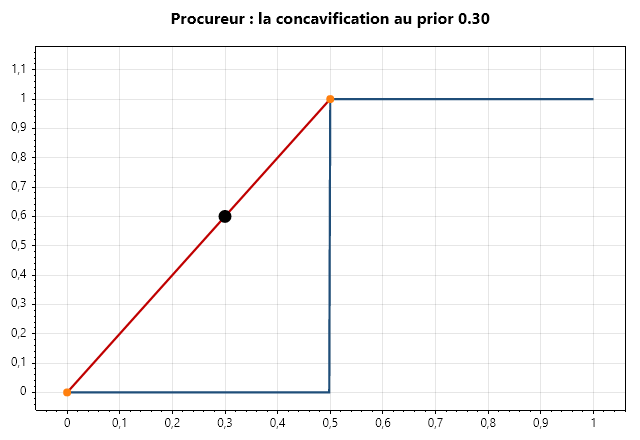


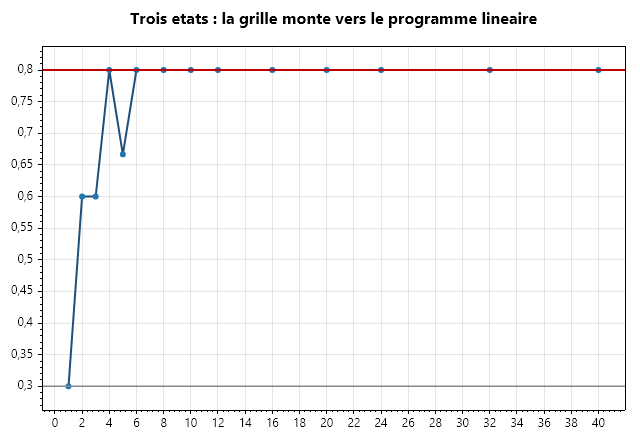

Panneau gauche -- posteriors du signal optimal du procureur :


  posterior [1 0] | masse 0,4000 | v = 0,0000


  posterior [0,5 0,5] | masse 0,6000 | v = 1,0000


  la corde au prior 0,30 vaut 0,6000 (sans information : 0,0000)


Panneau droit -- resolution -> valeur :


  N=  1 (   3 points) -> 0,300000 (ecart 5,000E-001)


... (10 outputs left out)

  N= 24 ( 325 points) -> 0,800000 (ecart 0,000E+000)


  N= 32 ( 561 points) -> 0,800000 (ecart -1,110E-016)


  N= 40 ( 861 points) -> 0,800000 (ecart 2,220E-016)



warning CS1701: En supposant que la référence d'assembly 'Microsoft.AspNetCore.Html.Abstractions, Version=2.3.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' utilisée par 'Microsoft.DotNet.Interactive' correspond à l'identité 'Microsoft.AspNetCore.Html.Abstractions, Version=10.0.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' de 'Microsoft.AspNetCore.Html.Abstractions', il se peut que vous deviez fournir une stratégie runtime

warning CS1701: En supposant que la référence d'assembly 'Microsoft.AspNetCore.Html.Abstractions, Version=2.3.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' utilisée par 'Microsoft.DotNet.Interactive' correspond à l'identité 'Microsoft.AspNetCore.Html.Abstractions, Version=10.0.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' de 'Microsoft.AspNetCore.Html.Abstractions', il se peut que vous deviez fournir une stratégie runtime



In [14]:
#r "nuget: ScottPlot, 5.0.55"
using ScottPlot;

// --- Panneau gauche : v(mu) du procureur (marche d'escalier), et le signal optimal
//     comme une corde qui passe au-dessus ; l'etoile marque le prior du carnet.
var plt1 = new ScottPlot.Plot();
double[] xs = Enumerable.Range(0, 501).Select(i => i / 500.0).ToArray();
double[] vs = xs.Select(x => Persuasion.ValeurPersuadeur(new[] { 1.0 - x, x }, uR_JEU, uS_PROC)).ToArray();
var marche = plt1.Add.Scatter(xs, vs);
marche.LineColor = ScottPlot.Color.FromHex("#1f4e79");
marche.LineWidth = 2.2F;
marche.MarkerSize = 0;

var postProc = Persuasion.Posteriors(M1.Sol.Q);
double[] px = postProc.Select(p => p.Posterior[1]).ToArray();
double[] pv = postProc.Select(p => Persuasion.ValeurPersuadeur(p.Posterior, uR_JEU, uS_PROC)).ToArray();
var corde = plt1.Add.Scatter(px, pv);
corde.LineColor = ScottPlot.Color.FromHex("#c00000");
corde.LineWidth = 2.2F;
corde.MarkerSize = 8;

double mu0p = INSTANCES["procureur"].Mu0[1];
var etoile = plt1.Add.Scatter(new[] { mu0p }, new[] { M1.Optimal });
etoile.LineWidth = 0;
etoile.MarkerSize = 13;
etoile.MarkerColor = ScottPlot.Color.FromHex("#000000");

plt1.Axes.SetLimits(-0.06, 1.06, -0.06, 1.18);
plt1.Title("Procureur : la concavification au prior 0.30");
display(HTML(plt1.GetPngHtml(640, 440)));

// --- Panneau droit : la grille monte vers la valeur du programme lineaire, sans
//     jamais la franchir ; la ligne pointillee grise est la divulgation complete.
var plt2 = new ScottPlot.Plot();
double[] resX = lignesConv.Select(t => (double)t.N).ToArray();
double[] valY = lignesConv.Select(t => t.V).ToArray();
var conv = plt2.Add.Scatter(resX, valY);
conv.LineColor = ScottPlot.Color.FromHex("#1f4e79");
conv.LineWidth = 2;
conv.MarkerSize = 6;
var plLine = plt2.Add.HorizontalLine(M3.Optimal);
plLine.Color = ScottPlot.Color.FromHex("#c00000");
plLine.LineWidth = 2;
var divLine = plt2.Add.HorizontalLine(M3.Divulgation);
divLine.Color = ScottPlot.Color.FromHex("#888888");
divLine.LineWidth = 1.6F;
plt2.Title("Trois etats : la grille monte vers le programme lineaire");
display(HTML(plt2.GetPngHtml(640, 440)));

// Les coordonnees des deux panneaux sont imprimees : la figure peut etre verifiee
// sans la regarder, et un ecart entre le trace et la mesure se voit ici.
Console.WriteLine("Panneau gauche -- posteriors du signal optimal du procureur :");
foreach (var p in postProc)
    Console.WriteLine($"  posterior [{Persuasion.Fmt(p.Posterior)}] | masse {p.Masse:F4} | "
                      + $"v = {Persuasion.ValeurPersuadeur(p.Posterior, uR_JEU, uS_PROC):F4}");
Console.WriteLine($"  la corde au prior {mu0p:F2} vaut {M1.Optimal:F4} "
                  + $"(sans information : {M1.SansInfo:F4})");
Console.WriteLine("Panneau droit -- resolution -> valeur :");
foreach (var (n, v, e, k) in lignesConv)
    Console.WriteLine($"  N={n,3} ({k,4} points) -> {v:F6} (ecart {e:E3})");


### Lecture de la figure

**À gauche**, la fonction $v$ du procureur est une marche d'escalier : $0$ sous le
seuil du juge, $1$ au-dessus. Le point du prior ($0{,}3$) est *sur la marche basse*,
et la corde rouge — le signal optimal — passe au-dessus. La hauteur du point étoilé
est la valeur du persuadeur ; l'écart vertical entre l'étoile et la marche est tout
ce que la persuasion rapporte ici.

**À droite**, la courbe bleue part exactement de la divulgation complète à
$N = 1$ (les sommets du simplexe) et monte vers la ligne rouge du programme
linéaire. Elle ne la franchit jamais. Les paliers visibles sont les résolutions où
le posterior optimal $(5, 2, 1)/8$ tombe juste : l'accord y devient exact, et les
résolutions intermédiaires rappellent que la grille est une restriction, pas une
méthode équivalente.


## 14. Ce que ce carnet établit — et ce qu'il ne prétend pas

**Établi, et falsifiable :**

1. **Les deux méthodes concordent** sur les trois instances, à la tolérance
   déclarée de $10^{-6}$ — et l'accord est *asserté* dans le carnet, pas seulement
   affiché. Le programme linéaire et la concavification ne partagent aucun code :
   l'un optimise sur la loi jointe, l'autre sur les combinaisons convexes d'une
   grille.
2. **La concavification sur grille est une approximation intérieure** : elle ne
   dépasse jamais le programme linéaire — à la tolérance numérique de $10^{-9}$
   près — ce qui est vérifié pour *chaque* résolution de la suite. Sa monotonie est
   **conditionnelle** : vraie le long des chaînes de divisibilité, fausse entre
   résolutions étrangères, et le couple $(4, 5)$ le mesure.
3. **La résolution 1 *est* la divulgation complète** : les sommets du simplexe sont
   les posteriors dégénérés, et l'ancrage est vérifié sur les deux instances où il
   a un sens. C'est ce qui interdit de traiter la méthode B comme une boîte noire.
4. **La persuasion n'est pas la transparence** : sur le procureur et sur les trois
   états, l'optimum dépasse **strictement** la divulgation complète et le signal
   optimal est **non partitionnel** — un même état envoie deux messages distincts.
   Sur le contrôle négatif aux préférences alignées, l'optimum **est** la
   divulgation complète et le signal optimal est partitionnel.
5. **La contrainte d'incitation est saturée à l'optimum** de l'instance à trois
   états : le persuadeur pousse le receveur jusqu'à l'indifférence, pas au-delà.

**Ce que le carnet ne fait pas** — des extensions, pas des oublis : pas de
persuasion **dynamique** (le persuadeur ne révèle qu'une fois), pas de **plusieurs
receveurs** (pas de jeu entre eux), pas de contrainte de crédibilité *ex post*
(le signal est engageant par hypothèse), pas de **vérifiabilité partielle** des
messages, pas de coût d'acquisition d'information. Chacune de ces variantes change
la formulation — et la concavification y survit rarement telle quelle.


## 15. Références

- **Kamenica, E. (2019).** *Bayesian Persuasion and Information Design.* Annual
  Review of Economics, 11, 249–272. — le cadre, la formulation par concavification
  et la lecture de la grille comme l'enveloppe concave de $v$.
- **Kamenica, E., & Gentzkow, M. (2011).** *Bayesian Persuasion.* American
  Economic Review, 101(6), 2590–2615. — l'article fondateur, et l'instance
  procureur / juge reprise ici.
- **Aumann, R. J., & Maschler, M. (1995).** *Repeated Games with Incomplete
  Information.* MIT Press. — la formulation de la loi jointe « état × message »
  qui rend le problème linéaire, et le principe de révélation utilisé en méthode A.

Ces trois références ne sont pas incluses dans le dépôt (droits d'édition) ; elles
sont citées, et la formulation du programme linéaire est une reconstitution
classique, pas une copie de code.


## Navigation

- Jumeau Python : [GameTheory-17e-Bayesian-Persuasion-Python](GameTheory-17e-Bayesian-Persuasion-Python.ipynb)
- Index de la série : [GameTheory](README.md)
